# 0.0 Imports

In [2]:
import inflection
from IPython.display       import Image as image
import lightgbm as lgb
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns

from boruta import BorutaPy
from collections import Counter
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn import metrics as mt
from sklearn.linear_model import LogisticRegression
from typing import List, Dict
from xgboost import XGBClassifier


## 0.1 Helper Functions

In [3]:
# Função para colocar o ponto perto do próximo mínimo multiplo de bucket_size
def bucketize(point: float, bucket_size:float) -> float:
    return bucket_size * math.floor(point / bucket_size)

# Função para colocar os pontos em bukets e conta o número de pontos em cada bucket
def make_histogram(points: List[float], bucket_size: float) -> Dict[float, int]:
    return Counter([bucketize(point, bucket_size) for point in points])

def plot_histogram(points: List[float], bucket_size: float, title: str=""):
    histogram = make_histogram(points, bucket_size)
    plt.bar(histogram.keys(), histogram.values(), width=bucket_size)
    plt.title(title)

# Função métricas de avaliação de modelos
def ml_metrics(model_name, y_true, y_prob, threshold =0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score(y_true, y_pred, zero_division=0)
    auc = mt.roc_auc_score(y_true, y_pred)

    return pd.DataFrame({
        'Model': model_name,
        'Accuracy': acc,
        'F1 Score': f1,
        'precision': prec,
        'Recall': rec,
        'AUC': auc
    }, index=[0])

## 0.2 Loading data

### 0.2.1 Data Train

In [4]:
df_raw = pd.read_csv('../dataset/train.csv')

In [5]:
df_raw.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
df_raw.dtypes

id                                     int64
Age                                    int64
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
Gender                                   str
Customer Type                            str
Type of Travel                           str
Class                                    str
satisfacti

### 0.2.2 Data Test

In [7]:
df_test = pd.read_csv('../dataset/test.csv')

# 1.0 DESCRICAO DOS DADOS

In [8]:
df1 = df_raw.copy()

In [9]:
df1.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

## 1.1 Rename columns

In [10]:

cols_old = [['id', 'Age', 'Flight Distance', 'Inflight wifi service',
             'Departure/Arrival time convenient', 'Ease of Online booking',
             'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 
             'Inflight entertainment', 'On-board service', 'Leg room service', 
             'Baggage handling', 'Checkin service', 'Cleanliness',
             'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
             'Customer Type', 'Type of Travel', 'Class', 'satisfaction']]

snakecase = lambda x: inflection.underscore( x.replace(" ", "_").replace("/", "_") )
cols_new = list(map(snakecase, cols_old[0]))

#rename
df1.columns = cols_new

In [11]:
cols_new

['id',
 'age',
 'flight_distance',
 'inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'cleanliness',
 'departure_delay_in_minutes',
 'arrival_delay_in_minutes',
 'gender',
 'customer_type',
 'type_of_travel',
 'class',
 'satisfaction']

## 1.2 Data Dimensions

In [12]:
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699635
Number of columns: 23


## 1.3 Data Types


In [13]:
df1.dtypes

id                                     int64
age                                    int64
flight_distance                        int64
inflight_wifi_service                  int64
departure_arrival_time_convenient      int64
ease_of_online_booking                 int64
gate_location                          int64
food_and_drink                         int64
online_boarding                        int64
seat_comfort                           int64
inflight_entertainment                 int64
on_board_service                       int64
leg_room_service                       int64
baggage_handling                       int64
checkin_service                        int64
cleanliness                            int64
departure_delay_in_minutes             int64
arrival_delay_in_minutes             float64
gender                                   str
customer_type                            str
type_of_travel                           str
class                                    str
satisfacti

In [14]:
#TRANSFORMANDO BOLEANO EM NÚMERO INTEIRO
df1['satisfaction'] = df1['satisfaction'].astype(int)

In [15]:
pd.set_option("display.max_columns", None)
df1.head()

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


## 1.4 Check NA


In [16]:
df1.isna().sum()

id                                     0
age                                    0
flight_distance                        0
inflight_wifi_service                  0
departure_arrival_time_convenient      0
ease_of_online_booking                 0
gate_location                          0
food_and_drink                         0
online_boarding                        0
seat_comfort                           0
inflight_entertainment                 0
on_board_service                       0
leg_room_service                       0
baggage_handling                       0
checkin_service                        0
cleanliness                            0
departure_delay_in_minutes             0
arrival_delay_in_minutes             292
gender                                 0
customer_type                          0
type_of_travel                         0
class                                  0
satisfaction                           0
dtype: int64

## 1.5 Fillout NA

In [17]:
#logica de preenchimento de valores nulos, caso o valor de 'Arrival Delay in Minutes' seja nulo, ele será preenchido com o valor de 'Departure Delay in Minutes'
# os valores de Arrival Delay in Minutes e Departure Delay in Minutes são muito próximos e com alta correlação, 
# então preencher os valores nulos de Arrival Delay in Minutes com os valores de Departure Delay in Minutes pode ser uma boa estratégia para lidar com os valores nulos.
# outra estratégia boa seria apagar esses campos, mas perde dados. A média não é estratégia boa por conta do desbalanceamento dos dados, a mediana também não é boa por conta do desbalanceamento dos dados, e o valor mais frequente também não é boa estratégia por conta do desbalanceamento dos dados.
c = "arrival_delay_in_minutes"
d = "departure_delay_in_minutes"
df1[c] = df1[c].fillna(df1[d])


In [18]:
df1.isna().sum()

id                                   0
age                                  0
flight_distance                      0
inflight_wifi_service                0
departure_arrival_time_convenient    0
ease_of_online_booking               0
gate_location                        0
food_and_drink                       0
online_boarding                      0
seat_comfort                         0
inflight_entertainment               0
on_board_service                     0
leg_room_service                     0
baggage_handling                     0
checkin_service                      0
cleanliness                          0
departure_delay_in_minutes           0
arrival_delay_in_minutes             0
gender                               0
customer_type                        0
type_of_travel                       0
class                                0
satisfaction                         0
dtype: int64

## 1.7 Descriptive Statistical

In [19]:
num_attributes = df1.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64'])

In [20]:
display(num_attributes)

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,57,612,2,1,1,1,1,3,3,2,2,2,2,2,4,0,0.0,0
699631,30,862,2,2,2,3,4,2,4,4,2,5,4,2,4,24,34.0,0
699632,49,3148,5,5,5,5,4,4,4,5,5,5,5,5,5,0,0.0,1
699633,61,679,5,2,2,2,5,4,4,5,4,5,5,5,1,0,0.0,1


In [21]:
display(cat_attributes)

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...
699630,Female,Loyal Customer,Business travel,Eco
699631,Female,disloyal Customer,Business travel,Eco
699632,Male,Loyal Customer,Business travel,Business
699633,Female,Loyal Customer,Business travel,Eco


## 1.7.1 Numerical Attributes

In [22]:
#numerical statistics
#Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T #média
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T #mediana


#Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T                      #desvio padrão
d2 = pd.DataFrame(num_attributes.apply(min)).T                         #min
d3 = pd.DataFrame(num_attributes.apply(max)).T                         #max
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T #range
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T          #skew
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T      #kurtosis

#Concatenar os dataframes de central tendency e dispersion
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [23]:
#dataframes de central tendency e dispersion
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,age,7.0,85.0,78.0,39.001928,40.0,13.800933,-0.049710,-0.738916
1,flight_distance,67.0,4983.0,4916.0,1353.778702,954.0,954.421884,1.080466,0.132785
2,inflight_wifi_service,0.0,5.0,5.0,2.778722,3.0,1.280418,0.088131,-0.795488
3,departure_arrival_time_convenient,0.0,5.0,5.0,3.156210,3.0,1.475389,-0.380044,-0.970400
4,ease_of_online_booking,0.0,5.0,5.0,2.813240,3.0,1.329549,0.040290,-0.877128
5,gate_location,0.0,5.0,5.0,3.013734,3.0,1.254014,-0.103855,-0.932468
6,food_and_drink,0.0,5.0,5.0,3.265644,3.0,1.300201,-0.186879,-1.088510
7,online_boarding,0.0,5.0,5.0,3.364156,4.0,1.288537,-0.464915,-0.658722
8,seat_comfort,0.0,5.0,5.0,3.568950,4.0,1.275332,-0.616192,-0.682405
9,inflight_entertainment,0.0,5.0,5.0,3.453910,4.0,1.308156,-0.466777,-0.921351


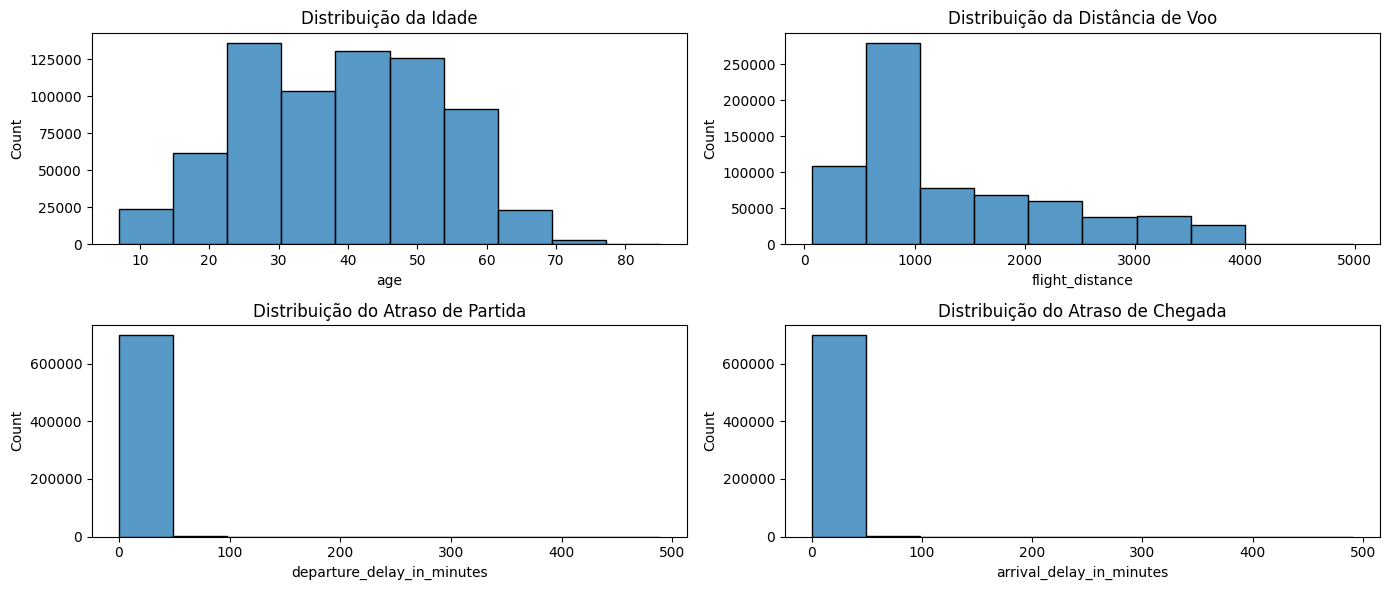

In [24]:
# Criar uma figura com 2 linhas e 2 colunas
fig, axes = plt.subplots(2, 2, figsize=(14, 6))

# Age
sns.histplot(df1['age'], bins=10, ax=axes[0, 0])
axes[0, 0].set_title('Distribuição da Idade')

# Distância de voo (flight distance)
sns.histplot(df1['flight_distance'], bins=10, ax=axes[0, 1])
axes[0, 1].set_title('Distribuição da Distância de Voo')

# Atraso de partida (departure delay)
sns.histplot(df1['departure_delay_in_minutes'], bins=10, ax=axes[1, 0])
axes[1, 0].set_title('Distribuição do Atraso de Partida')

# Atraso de chegada (arrival delay)
sns.histplot(df1['arrival_delay_in_minutes'], bins=10, ax=axes[1, 1])
axes[1, 1].set_title('Distribuição do Atraso de Chegada')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

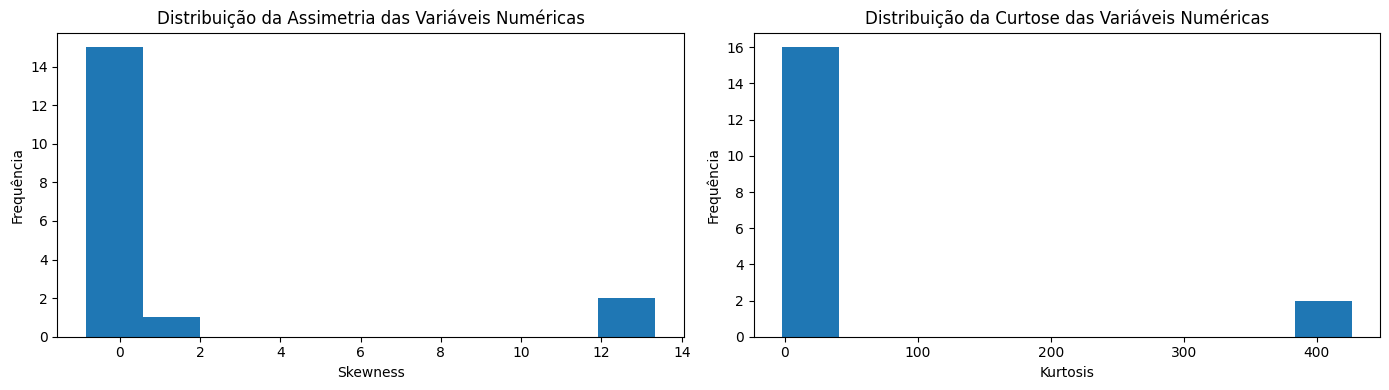

In [25]:
# Criar uma figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma Skewness (Assimetria): negativo = cauda esquerda, positivo = cauda direita, 0 = simetria
axes[0].hist(d5.T.values.flatten(), bins=10)
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Assimetria das Variáveis Numéricas')
axes[0].set_xlabel('Skewness')

# Histograma Kurtosis (Curtose): relacionada ao comportamento das caudas e à ocorrência de valores extremos
axes[1].hist(d6.T.values.flatten(), bins=10)
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição da Curtose das Variáveis Numéricas')
axes[1].set_xlabel('Kurtosis')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 1.7.2 Categorical Attributes

In [26]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

<Axes: xlabel='gender', ylabel='satisfaction'>

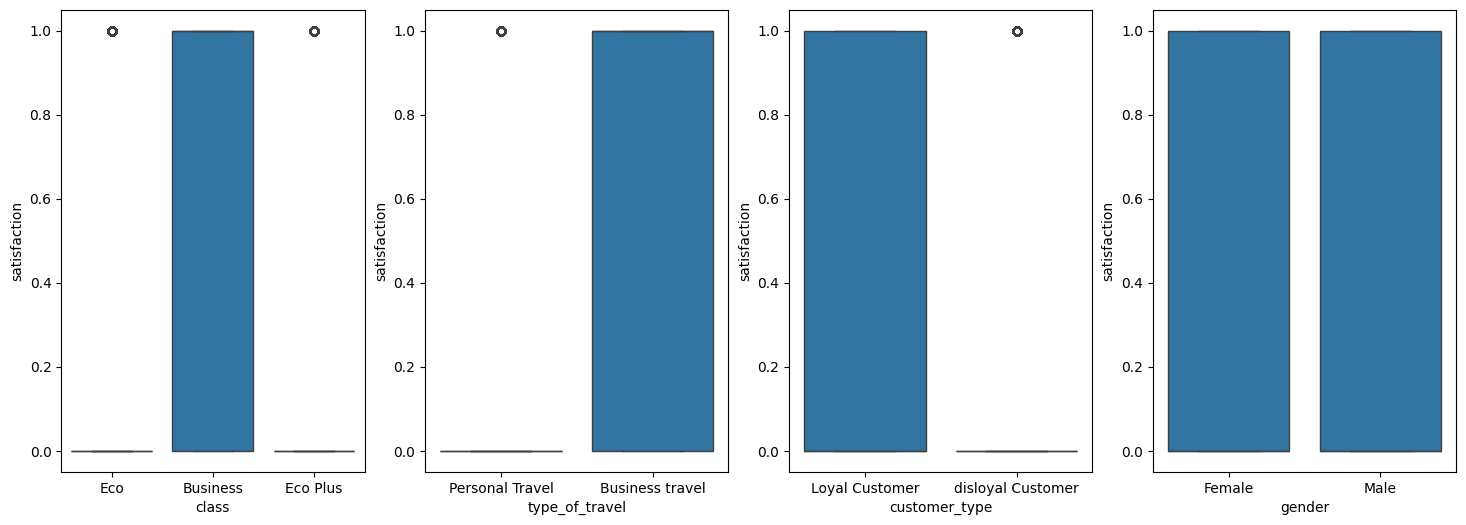

In [27]:
#boxplot
aux1 = pd.concat([cat_attributes, df1['satisfaction']], axis=1)

plt.figure(figsize=(18, 6))
plt.subplot(1, 4, 1)
sns.boxplot(x='class', y='satisfaction', data=aux1)

plt.subplot(1, 4, 2)
sns.boxplot(x='type_of_travel', y='satisfaction', data=aux1)

plt.subplot(1, 4, 3)
sns.boxplot(x='customer_type', y='satisfaction', data=aux1)

plt.subplot(1, 4, 4)
sns.boxplot(x='gender', y='satisfaction', data=aux1)

# 2.0 FEATURE ENGINEERING

## Mapa mental de hipóteses

- Fenômeno: Satisfação do cliente (variável dependente ou resposta = y).
- Agentes: Variáveis que impactam o fenômeno (variáveis independentes = x)
- Atributos do agente: características dos atributos.

## 2.1 Criação das hipóteses

22 Hipóteses foram geradas considerando três frentes: conveniência, serços a bordo e perfil do viajante.
Para vadiação ou refutação do teste de crenças.

## 2.2 Lista final de hipóteses

### Feature Engineering

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

## 3.1 Análise Exploratória Univariada

# 4.0. FEATURE SELECTION

## 4.1. Filter Method

## 4.2 Wrapper Method Boruta

## 4.3 Wrapper Method RFECV

## 4.4. Final Features Selection

# 5.0. Preparação dos Dados

## 5.1. Separação entre Treinamento e validação

## 5.2. Padronização - teste de normalidade

### Teste de normalidade shapiro-Wilk e kosmogorov-Smirnov

### Rescaling

## 5.3. Encoder

# 6.0. Machine Learning Modeling

## 6.1. Baseline Model

## 6.2 Regressão Logística

## 6.3. Random Forest

## 6.4. LGBM Classifier

## 6.5. XGBoost